# Twelfth Night Networks, Part 1: Who Shares the Stage?
**CTS 2000 Group Project · Visualization 2 (interactions as networks) · Krish's part**


**What this notebook does.** It builds the networks from **who is on stage together** (**A**, co-presence) and from Kim's rule *"everyone on stage hears the speaker"* (**K**), and uses them to answer our three research questions.

**What comes next.** This is Part 1 of our Visualization 2 work. Part 2 (Myra's notebook) uses the same play, layout and colours, but builds networks from *who actually talks to whom* instead of who shares the stage. Reading the two together lets us compare "being in the room" with "being in the conversation".

## Research questions
1. **RQ1.** How do conversations change from Act 1 to Act 5? Do they get more chaotic and then settle?
2. **RQ2.** How separate are Orsino's court and Olivia's household? Who connects them?
3. **RQ3.** What changes if Viola and Cesario are treated as two people? What did the disguise let her do?

## How this builds on our earlier work
- **Short paper.** It argues that Kim's rule misreads hiding, eavesdropping and asides, and that merging Viola and Cesario hides the disguise. This notebook builds the co-presence side of that comparison and splits Viola/Cesario.
- **Code reproduction (Kim 2024).** We rebuilt Kim's onstage and exchange matrices and check them against the files he published (Section 2.2), plus the centralization numbers from the reproduction video.

## How this fits the course
| What we do | Source |
|---|---|
| `lxml` + XPath to read TEI XML, `defaultdict`, `Counter`, regular expressions | course, Week 8 `5-5_TEI_XML_networks` |
| Nested `defaultdict` counts turned into a `pd.DataFrame`, `nx.Graph()` + `add_edge`, `nx.draw_networkx` with a `pos` dictionary, `degree`, `density` | course, Week 8 `5-5_TEI_XML_networks` |
| `pandas` `groupby`, `matplotlib` line and bar charts | course, Week 6 `6-1_pandas` and Week 8 `3-2_data_viz` |
| Entrance/exit tracking, onstage and exchange matrices, centralization functions | **from our short paper** (Kim 2024, rebuilt in our code reproduction); not course code |
| Louvain communities, betweenness, "remove a character" distance test (shortest paths) | **beyond the course** (NetworkX documentation) |
| The Viola/Cesario rule (`persona_at`) | **our own** |


**Setup.** The course environment plus `lxml` and `requests`.

## Presenting
In one sentence per section: (1) we load the play; (2) we turn it into tables of who is on stage; (3.1) we draw who shares the stage; (3.2) we see how that changes by act; (3.3) we ask who connects the two households; (3.4) we split Viola and Cesario; (3.5) we show the letter scene where "everyone hears" goes wrong.

---
# 1. Dataset and question

We use the Folger edition of *Twelfth Night* in TEI XML. The course points to the Folger Digital Texts site for this kind of file; we take the copy that Kim (2024) published in his repository.

*Sections 1 and 2 load the play and build the two networks this part needs (A and K).*

In [1]:
import os, re, requests
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from lxml import etree

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

XML_URL = ("https://raw.githubusercontent.com/hkim1596/shakespearean_character_network/"
           "main/data/Twelfth%20Night.xml")          # fix #1 from the reproduction: real file name
XML_PATH = "data/Twelfth Night.xml"
os.makedirs("data", exist_ok=True)
# only download the play if we don't already have it
if not os.path.exists(XML_PATH):
    response = requests.get(XML_URL)
    response.raise_for_status()                     # a failed download now stops right here
    with open(XML_PATH, "wb") as f:
        f.write(response.content)
print("XML file:", XML_PATH, "-", os.path.getsize(XML_PATH), "bytes")

XML file: data/Twelfth Night.xml - 2685594 bytes


### What is in the data?
Three kinds of tags matter to us:
- `<sp who="#Orsino_TN">`: a **speech**, with its speaker
- `<stage type="entrance|exit|business|delivery">`: **stage directions**; `delivery` holds things like "aside" and "to Maria"
- `<milestone unit="ftln" ana="#verse">`: a **line marker**, tagged verse or prose

In [2]:
TEI = "{http://www.tei-c.org/ns/1.0}"
XMLID = "{http://www.w3.org/XML/1998/namespace}id"
root = etree.parse(XML_PATH).getroot()

first_sp = root.find(f".//{TEI}sp")
print(etree.tostring(first_sp, pretty_print=True).decode()[:900])

print("Stage-direction types:", dict(Counter(s.get("type") for s in root.iter(TEI + "stage"))))

<sp xmlns="http://www.tei-c.org/ns/1.0" xml:id="sp-0001" who="#Orsino_TN">
<speaker xml:id="spk-0001">
<w xml:id="w0000340">ORSINO</w>
</speaker>
<ab xml:id="ab-0001">
<lb xml:id="lb-00006"/>
<milestone unit="ftln" xml:id="ftln-0001" n="1.1.1" ana="#verse" corresp="#w0000350 #c0000360 #w0000370 #c0000380 #w0000390 #c0000400 #w0000410 #c0000420 #w0000430 #c0000440 #w0000450 #c0000460 #w0000470 #p0000480 #c0000490 #w0000500 #c0000510 #w0000520 #p0000530"/>
<w xml:id="w0000350" n="1.1.1">If</w>
<c xml:id="c0000360" n="1.1.1"> </c>
<w xml:id="w0000370" n="1.1.1">music</w>
<c xml:id="c0000380" n="1.1.1"> </c>
<w xml:id="w0000390" n="1.1.1">be</w>
<c xml:id="c0000400" n="1.1.1"> </c>
<w xml:id="w0000410" n="1.1.1">the</w>
<c xml:id="c0000420" n="1.1.1"> </c>
<w xml:id="w0000430" n="1.1.1">food</w>
<c xml:id="c0000440" n="1.1.1"> </c>
<w xml:id="w0000450" n="1.1.1">of</w>
<c xml:id="c0000460" n
Stage-direction types: {'entrance': 62, 'exit': 62, 'business': 49, 'delivery': 120, 'mixed': 1}


# 2. Methods

## 2.1 Parsing the play into a *speech table*

One pass through the XML, in document order, does three jobs:
1. **Kim's logic.** Keep a list of who is on stage: entrances add names, exits remove them. Save a snapshot at every line marker.
2. **Our additions.** For each speech, record act, scene, words, verse/prose, and whether Viola is speaking as **Viola or Cesario**.

In [3]:
def clean_id(raw):
    """'#Orsino_TN' -> 'Orsino' (same cleaning as Kim's code)."""
    return re.sub(r"_[^\s,]*", "", raw.replace("#", ""))

def who_list(el):
    return [clean_id(w) for w in el.get("who", "").split()]

def speech_text(sp):
    """Words and punctuation of a speech, leaving out stage directions and the speaker label."""
    out = ""
    for node in sp.iter(TEI + "w", TEI + "pc"):
        if any(a.tag in (TEI + "stage", TEI + "speaker") for a in node.iterancestors()):
            continue
        out += (node.text or "") if node.tag == TEI + "pc" else " " + (node.text or "")
    return out.strip()

def persona_at(on_stage, act, scene, revealed):
    """Is Viola 'Viola' or 'Cesario' at this moment?
    Viola when she speaks as herself (scene 1.2, after her reveal in 5.1, or when only the
    Captain / nobody else is on stage). Cesario whenever anyone else is watching."""
    if (act, scene) == (1, 2) or revealed:
        return "Viola"
    # basically: if anyone besides the Captain is around, she is acting as Cesario
    return "Viola" if not (set(on_stage) - {"Viola", "Captain"}) else "Cesario"

In [4]:
def parse_play(root):
    # running list of who is on stage right now (same idea as Kim's code)
    on_stage = []
    timeline, ftln_meta, stage_events, speeches = {}, {}, [], []
    act = scene = None
    revealed, last_ftln = False, None

    for el in root.iter(TEI + "div1", TEI + "div2", TEI + "sp", TEI + "stage", TEI + "milestone"):
        if el.tag == TEI + "div1":
            act = int(el.get("n"))
        elif el.tag == TEI + "div2":
            scene = int(el.get("n"))

        elif el.tag == TEI + "milestone" and el.get("unit") == "ftln":
            fid = el.get(XMLID); last_ftln = fid
            timeline[fid] = list(on_stage)                      # Kim: snapshot of who is on stage
            ftln_meta[fid] = dict(act=act, scene=scene, n=el.get("n"), ana=el.get("ana"),
                                  persona=persona_at(on_stage, act, scene, revealed))

        elif el.tag == TEI + "stage":
            typ, who = el.get("type"), who_list(el)
            text = " ".join("".join(el.itertext()).split())
            if typ == "entrance" and el.get("who") is not None:
                on_stage = list(set(on_stage + who))
            elif typ == "exit" and el.get("who") is not None:
                on_stage = [c for c in on_stage if c not in who]
            if typ in ("entrance", "exit") and who:
                stage_events.append(dict(act=act, scene=scene, type=typ, n_chars=len(who), who=who))

        elif el.tag == TEI + "sp":
            speakers = who_list(el)
            speaker = speakers[0]
            ab = el.find(".//" + TEI + "ab")
            n_words = len(re.findall(r"\S+", "".join(ab.itertext()))) // len(speakers) if ab is not None else 0
            text = speech_text(el)

            if speaker == "Viola" and act == 5 and scene == 1 and re.search(r"\bI am Viola\b", text):
                revealed = True
            ms = [m.get("ana") for m in el.iter(TEI + "milestone") if m.get("unit") == "ftln"]
            persona = persona_at(on_stage, act, scene, revealed)

            # ---- Network K: Kim's rule, everyone else on stage hears (self if alone) ----
            aud_kim = [c for c in on_stage if c != speaker] or [speaker]

            speeches.append(dict(sp_id=el.get(XMLID), act=act, scene=scene, speaker=speaker, n_words=n_words,
                                 verse_lines=ms.count("#verse"), prose_lines=ms.count("#prose"),
                                 n_lines=len(ms), first_ftln=last_ftln, persona=persona,
                                 on_stage=list(on_stage), aud_kim=aud_kim, text=text))
    sp_df = pd.DataFrame(speeches)
    return sp_df, timeline, pd.DataFrame(ftln_meta).T, pd.DataFrame(stage_events)

speeches, timeline, ftln_meta, stage_events = parse_play(root)
print(f"{len(speeches)} speeches, {len(timeline)} line markers, {len(stage_events)} entrance/exit directions")
speeches[["act", "scene", "speaker", "n_words", "persona", "aud_kim", "text"]].head(8)

926 speeches, 2634 line markers, 124 entrance/exit directions


,act,scene,speaker,n_words,persona,aud_kim,text
0,1,1,Orsino,136,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO, ATTENDANTS.ORSI...","If music be the food of love, play on. Give me..."
1,1,1,ATTENDANTS.ORSINO.Curio,8,Cesario,"[Orsino, MUSICIANS, ATTENDANTS.ORSINO]","Will you go hunt, my lord?"
2,1,1,Orsino,4,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO, ATTENDANTS.ORSI...","What, Curio?"
3,1,1,ATTENDANTS.ORSINO.Curio,3,Cesario,"[Orsino, MUSICIANS, ATTENDANTS.ORSINO]",The hart.
4,1,1,Orsino,69,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO, ATTENDANTS.ORSI...","Why, so I do, the noblest that I have. O, when..."
5,1,1,ATTENDANTS.ORSINO.Valentine,80,Cesario,"[MUSICIANS, Orsino, ATTENDANTS.ORSINO, ATTENDA...","So please my lord, I might not be admitted, Bu..."
6,1,1,Orsino,88,Cesario,"[MUSICIANS, ATTENDANTS.ORSINO.Valentine, ATTEN...","O, she that hath a heart of that fine frame To..."
7,1,2,Viola,8,Viola,"[Captain, SAILORS]","What country, friends, is this?"


**The columns:** `aud_kim` = who hears the speech if *everyone on stage* does (Kim's rule, **K**) · `persona` = Viola or Cesario at that moment · `on_stage` = everyone on stage when the speech starts.

## 2.2 Shared network tools
One small set of functions builds both networks from the speech table. Each network is a table of weights between pairs of characters:

| Network | Edge between two characters = |
|---|---|
| **A. Co-presence** | lines they share the stage (Kim's *onstage* matrix) |
| **K. Everyone hears** | words spoken, heard by *everyone* on stage (Kim's *exchange* matrix) |


In [5]:
def relabel(name, persona, split):
    """With split=True, 'Viola' becomes 'Viola' or 'Cesario' depending on the moment."""
    return persona if (split and name == "Viola") else name

def presence_matrix(split=False, act=None, scene=None):
    """Lines x characters (1 = on stage). Kim's stage_timeline."""
    rows = {}
    for fid, chars in timeline.items():
        m = ftln_meta.loc[fid]
        if (act and m["act"] != act) or (scene and m["scene"] != scene):
            continue
        rows[fid] = {relabel(c, m["persona"], split): 1 for c in chars}
    return pd.DataFrame(rows).T.fillna(0).astype(int).sort_index(axis=1)   # sorted = repeatable

def copresence(split=False, act=None, scene=None):
    """Kim's onstage matrix: lines x characters, multiplied by itself = lines each pair shares the stage."""
    X = presence_matrix(split, act, scene)
    M = X.to_numpy(copy=True).T @ X.to_numpy(copy=True)          # fix #2 from the reproduction: work on a copy
    np.fill_diagonal(M, 0)
    return pd.DataFrame(M, index=X.columns, columns=X.columns)

def exchange(key, split=False, act=None, scene=None):
    """Directed word counts speaker -> listener (key = aud_kim, Kim's everyone-hears rule)."""
    ex = defaultdict(lambda: defaultdict(int))
    for r in speeches.itertuples():
        if (act and r.act != act) or (scene and r.scene != scene):
            continue
        s = relabel(r.speaker, r.persona, split)
        for l in getattr(r, key):
            ex[s][relabel(l, r.persona, split)] += r.n_words
    return pd.DataFrame(ex).T.fillna(0).sort_index().sort_index(axis=1)

def symmetric(ex):
    """Turn 'A spoke to B' counts into 'A and B talked' counts (both directions added together)."""
    both = defaultdict(lambda: defaultdict(int))
    for s in ex.index:
        for l in ex.columns:
            if s != l and ex.loc[s, l] > 0:
                both[s][l] += ex.loc[s, l]
                both[l][s] += ex.loc[s, l]
    nodes = sorted(set(ex.index) | set(ex.columns))
    return pd.DataFrame(both, index=nodes, columns=nodes).fillna(0).astype(int)

# one dictionary per network so we can put them side by side
def build_networks(split=False, act=None, scene=None):
    return {"A. Co-presence": copresence(split, act, scene),
            "K. Kim's exchange": symmetric(exchange("aud_kim", split, act, scene))}

# only people who actually talk (the musicians and sailors never do)
SPEAKING = set(speeches["speaker"])
SHORT = {"TobyBelch": "Toby", "AndrewAguecheek": "Andrew", "ATTENDANTS.ORSINO.Curio": "Curio",
         "ATTENDANTS.ORSINO.Valentine": "Valentine", "ATTENDANTS.OLIVIA.1": "Attendant",
         "OFFICERS.1": "Officer 1", "OFFICERS.2": "Officer 2"}
short = lambda n: SHORT.get(n, n)

def to_graph(M, keep=None):
    """Table of weights -> networkx graph, built edge by edge like the course notebook 5-5."""
    keep = keep or (SPEAKING | {"Cesario"})
    G = nx.Graph()
    for a in M.index:
        if a in keep:
            G.add_node(short(a))                          # keep characters even if they have no links
    for a in M.index:
        for b in M.columns:
            if a in keep and b in keep and a != b and M.loc[a, b] > 0:
                G.add_edge(short(a), short(b), weight=M.loc[a, b])
    return G

### Check against Kim's published output (the reproduction)
If our rebuilt version of Kim's two networks is right, it should match the files in his repository exactly. This is the same check we did in the code reproduction.

In [6]:
AUTHOR = "https://raw.githubusercontent.com/hkim1596/shakespearean_character_network/main/"
def author_csv(path):
    try:
        return pd.read_csv(AUTHOR + path.replace(" ", "%20"), index_col=0)
    except Exception as e:
        print("  (could not download", path, "-", type(e).__name__, ")")
        return None

# optional sanity check: these should match Kim's own files from our reproduction
onstage_author = author_csv("output_onstage/Twelfth Night_onstage.csv")
exchange_author = author_csv("output_exchange/Twelfth Night_exchange.csv")

if onstage_author is not None:
    mine = presence_matrix().T.reindex(index=onstage_author.index, columns=onstage_author.columns, fill_value=0)
    print("On-stage presence (characters x lines) identical to the author's:",
          bool((mine.to_numpy() == onstage_author.astype(int).to_numpy()).all()))
if exchange_author is not None:
    mine = exchange("aud_kim").reindex(index=exchange_author.index, columns=exchange_author.columns, fill_value=0)
    print("Exchange matrix (words) identical to the author's:",
          bool(np.allclose(mine.to_numpy(), exchange_author.to_numpy())))

On-stage presence (characters x lines) identical to the author's: True
Exchange matrix (words) identical to the author's: True


And the whole-play centralization numbers from the reproduction video (degree 0.3619, betweenness 0.0210), computed on Kim's matrix with every node (musicians and sailors included):

In [7]:
def degree_centralization(G):                     # Kim's function
    degrees = nx.degree(G)
    max_degree = max(dict(degrees).values())
    total = sum(max_degree - d for _, d in degrees)
    n = len(G.nodes)
    return total / ((n - 1) * (n - 2)) if n > 2 else 0

def betweenness_centralization(G):                # Kim's function
    b = nx.betweenness_centrality(G)
    mx = max(b.values())
    total = sum(mx - v for v in b.values())
    n = len(G.nodes)
    return total / ((n - 1) * (n - 2) / 2) if n > 2 else 0

A_all = copresence()
G_kim = to_graph(A_all, keep=set(A_all.index))       # every node, like Kim
print(f"Degree centralization:      {degree_centralization(G_kim):.4f}   (code reproduction video: 0.3619)")
print(f"Betweenness centralization: {betweenness_centralization(G_kim):.4f}   (code reproduction video: 0.0210)")

Degree centralization:      0.3619   (code reproduction video: 0.3619)
Betweenness centralization: 0.0210   (code reproduction video: 0.0210)


# 3. Results

## 3.0 Drawing the networks: one layout, one colour code
Every picture uses the **same node positions** (court on the left, Olivia's household on the right, characters who belong to neither in the middle), so when two networks look different it is because their *edges* differ, not because the layout moved. Node size = how much interaction a character has; edge width = how much interaction a pair has; Viola/Cesario is outlined in red.

In [8]:
COURT = {"Orsino", "Curio", "Valentine"}
HOUSEHOLD = {"Olivia", "Maria", "Malvolio", "Toby", "Andrew", "Fabian", "Attendant"}
side = lambda n: "court" if n in COURT else "household" if n in HOUSEHOLD else "unaligned"
SIDE_COLOR = {"court": "#e0a800", "household": "#3b6fb6", "unaligned": "#9bb5a0"}

nets = build_networks()
# same networks again, but Viola and Cesario count as two different people
nets_split = build_networks(split=True)

# Fixed positions (x, y) for every character: court on the left, household on the right,
# Viola in the middle. Placed by hand so every figure uses the same picture.
POS = {
    "Orsino": (-3.16, 0.52), "Curio": (-2.01, 0.14), "Valentine": (-2.92, -0.66),                      # court
    "Viola": (0.0, 0.0), "Cesario": (0.35, -0.45), "Feste": (-0.99, 0.92), "Captain": (0.1, 1.35),     # neither / both
    "Antonio": (1.11, 0.76), "Sebastian": (1.29, -0.4), "Priest": (0.5, -1.26),
    "Officer 1": (-1.33, -0.2), "Officer 2": (-0.67, -1.17),
    "Olivia": (2.67, -1.1), "Maria": (1.82, -0.66), "Malvolio": (1.63, 0.27), "Fabian": (2.25, 1.0),   # household
    "Attendant": (3.2, 0.98), "Andrew": (3.78, 0.22), "Toby": (3.54, -0.71),
}

def draw_net(G, ax, title="", pos=POS, label_size=9, scale=1.0, max_w=None):
    """Draw a network on our fixed layout (same nx.draw_networkx call as the course notebook)."""
    weights = [d["weight"] for _, _, d in G.edges(data=True)]
    top = max_w or max(weights, default=1)
    strength = dict(G.degree(weight="weight"))                 # total interaction of each character
    nx.draw_networkx(G, pos, ax=ax, font_size=label_size, edge_color="#999999",
                     width=[0.3 + 6 * scale * (w / top) ** 0.7 for w in weights],      # thicker = more interaction
                     node_color=[SIDE_COLOR[side(n)] for n in G.nodes],
                     node_size=[160 + 9 * strength[n] ** 0.5 for n in G.nodes],        # bigger = more interaction
                     edgecolors=["#c0392b" if n in ("Viola", "Cesario") else "white" for n in G.nodes],
                     linewidths=[3 if n in ("Viola", "Cesario") else 1 for n in G.nodes])
    ax.set_title(title, fontsize=12); ax.axis("off")

def legend(ax):
    for s, c in SIDE_COLOR.items(): ax.scatter([], [], c=c, s=90, label={"court": "Orsino's court", "household": "Olivia's household", "unaligned": "neither / both"}[s])
    ax.legend(loc="lower center", ncol=3, frameon=False, fontsize=10)

## 3.1 The whole play: sharing a stage vs. being heard by everyone
- **A. Co-presence**: who shares the stage.
- **K. Everyone hears**: Kim's exchange rule, where a speech counts as spoken to *everyone* on stage.

*In one sentence:* both pictures are almost the same, because everyone who shares a stage also "hears" everyone who speaks.

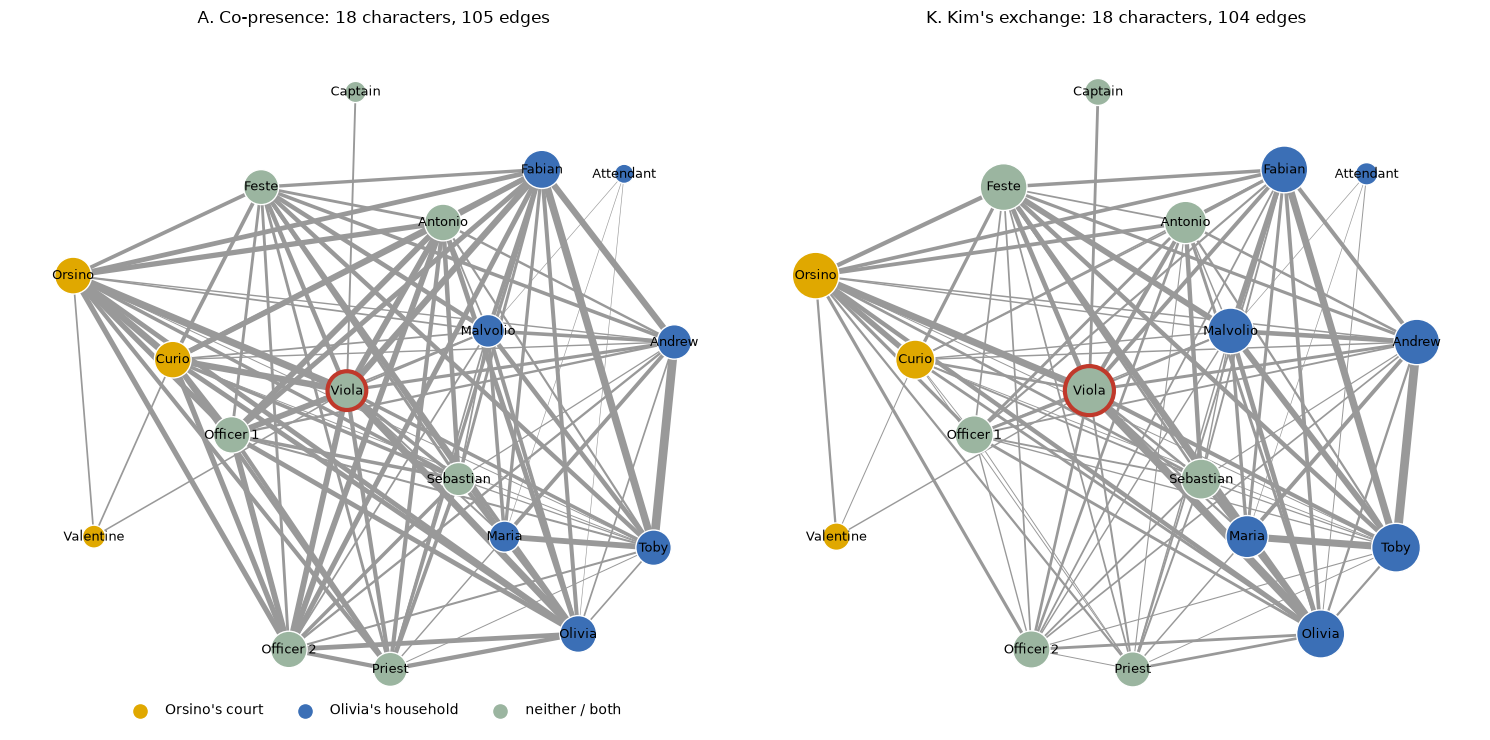

In [9]:
# two ways of counting a connection, drawn on the same layout
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, name in zip(axes, ["A. Co-presence", "K. Kim's exchange"]):
    G = to_graph(nets[name])                     # turn the table of weights into a graph
    draw_net(G, ax, f"{name}: {G.number_of_nodes()} characters, {G.number_of_edges()} edges")
legend(axes[0]); plt.tight_layout(); plt.show()

**Do the algorithm's groups match the two households?** We run Louvain (NetworkX built-in, `seed=42` so it is repeatable) on the co-presence network and compare with our court/household map.

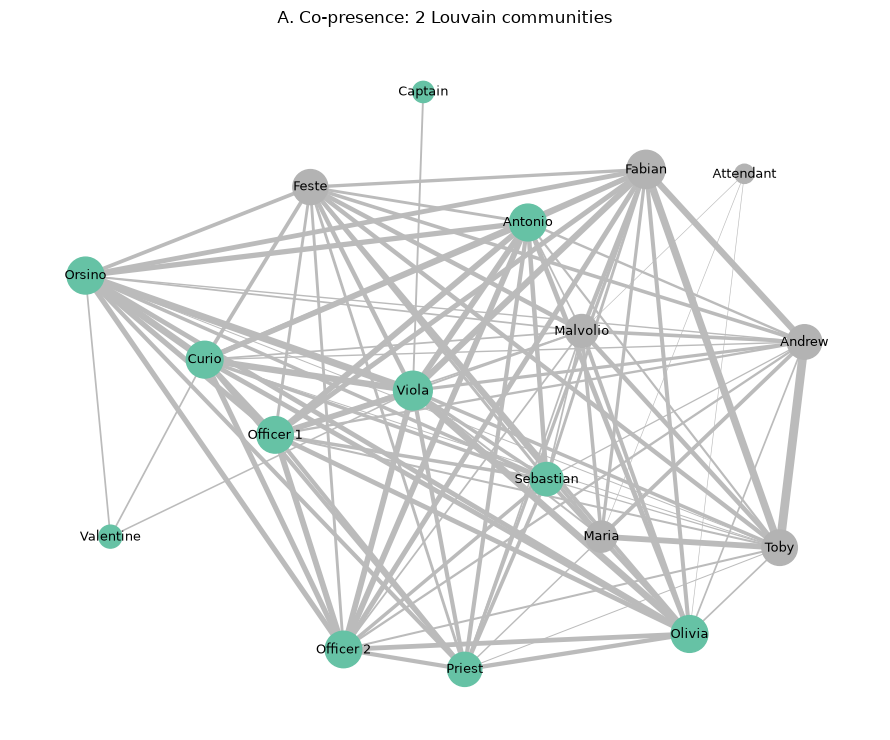

['Antonio', 'Captain', 'Curio', 'Officer 1', 'Officer 2', 'Olivia', 'Orsino', 'Priest', 'Sebastian', 'Valentine', 'Viola']
['Andrew', 'Attendant', 'Fabian', 'Feste', 'Malvolio', 'Maria', 'Toby']


In [10]:
G = to_graph(nets["A. Co-presence"])
comms = nx.community.louvain_communities(G, weight="weight", seed=42)   # groups of characters who interact a lot
color = {n: i for i, c in enumerate(comms) for n in c}

fig, ax = plt.subplots(figsize=(9, 7.5))
weights = [d["weight"] for _, _, d in G.edges(data=True)]
nx.draw_networkx(G, POS, ax=ax, font_size=9, edge_color="#bbbbbb",
                 width=[0.3 + 6 * (w / max(weights)) ** 0.7 for w in weights],
                 node_color=[color[n] for n in G.nodes], cmap=plt.cm.Set2,          # one colour per community
                 node_size=[160 + 9 * G.degree(n, weight="weight") ** 0.5 for n in G.nodes])
ax.set_title(f"A. Co-presence: {len(comms)} Louvain communities"); ax.axis("off")
plt.tight_layout(); plt.show()
for c in sorted(comms, key=len, reverse=True):
    print(sorted(c))

## 3.2 RQ1: how do conversations change from Act 1 to Act 5?
**One co-presence network per act**, same layout.

*In one sentence:* the stage fills up act by act until, in Act 5, almost everyone is there together.

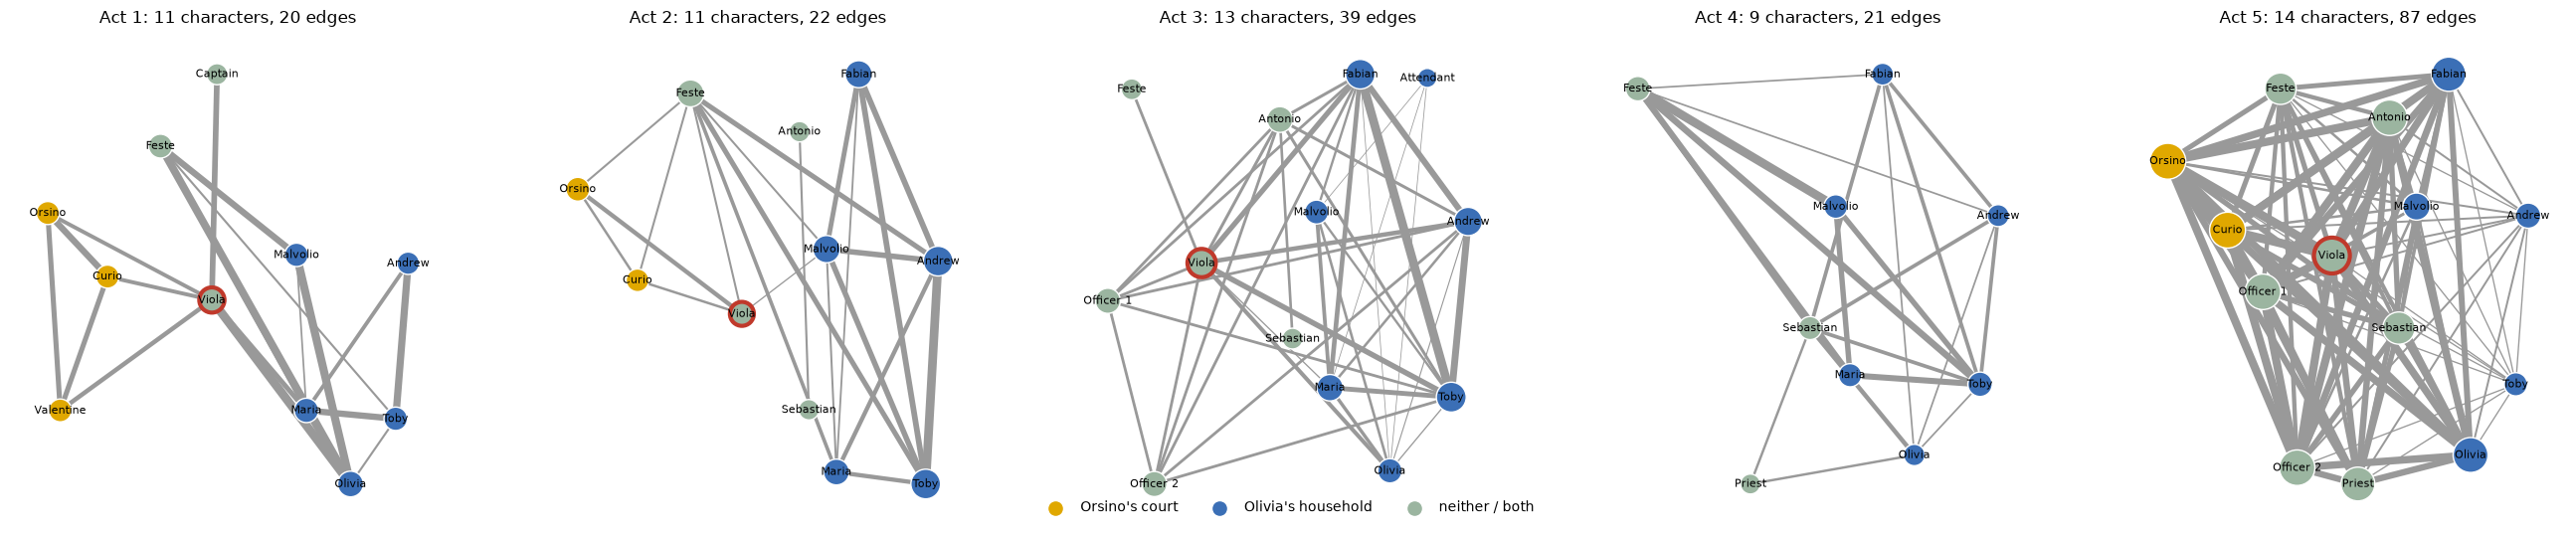

In [11]:
# one network per act, all on the same layout
fig, axes = plt.subplots(1, 5, figsize=(26, 5.5))
for act in range(1, 6):
    na = build_networks(act=act)
    G = to_graph(na["A. Co-presence"])
    G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])     # leave out characters who are not in this act
    draw_net(G, axes[act - 1], f"Act {act}: {G.number_of_nodes()} characters, {G.number_of_edges()} edges", label_size=8)
legend(axes[2]); plt.tight_layout(); plt.show()

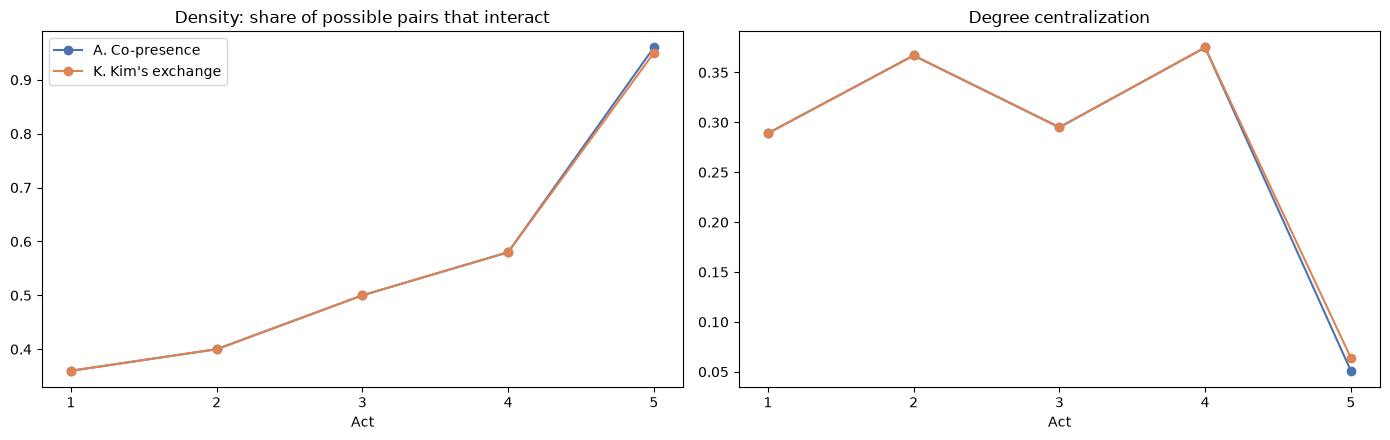

characters                            edges                          density                         top_character                  
network A. Co-presence K. Kim's exchange A. Co-presence K. Kim's exchange A. Co-presence K. Kim's exchange      A. Co-presence K. Kim's exchange
act                                                                                                                                             
1                   11                11             20                20           0.36              0.36              Olivia            Olivia
2                   11                11             22                22            0.4               0.4         Andrew/Toby              Toby
3                   13                13             39                39            0.5               0.5                Toby              Toby
4                    9                 9             21                21           0.58              0.58               Feste             Feste
5                   14                14             87                86           0.96              0.95  Curio/Orsino/Viola            Orsino

In [12]:
def net_summary(M):
    G = to_graph(M); n = G.number_of_nodes()
    strength = dict(G.degree(weight="weight")); top = max(strength.values()) if n else 0
    return dict(characters=n, edges=G.number_of_edges(), density=round(nx.density(G), 2),   # share of possible pairs that interact
                degree_centralization=round(degree_centralization(G), 3),                   # Kim's function from above
                top_character="/".join(sorted(k for k, v in strength.items() if abs(v - top) < 1e-9)))   # ties shown together

rows = []
for act in range(1, 6):
    na = build_networks(act=act)
    for name in ["A. Co-presence", "K. Kim's exchange"]:
        rows.append(dict(act=act, network=name, **net_summary(na[name])))
per_act = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, c in zip(["A. Co-presence", "K. Kim's exchange"], ["#4c72b0", "#dd8452"]):
    d = per_act[per_act.network == name]
    axes[0].plot(d.act, d.density, marker="o", color=c, label=name)
    axes[1].plot(d.act, d.degree_centralization, marker="o", color=c, label=name)
axes[0].set_title("Density: share of possible pairs that interact"); axes[1].set_title("Degree centralization")
for ax in axes: ax.set_xlabel("Act"); ax.set_xticks(range(1, 6))
axes[0].legend(); plt.tight_layout(); plt.show()
per_act.pivot(index="act", columns="network", values=["characters", "edges", "density", "top_character"])

**Chaos, scene by scene.** Three numbers per scene: entrances and exits per 100 lines (how much people come and go), how many different people speak, and how long speeches are.

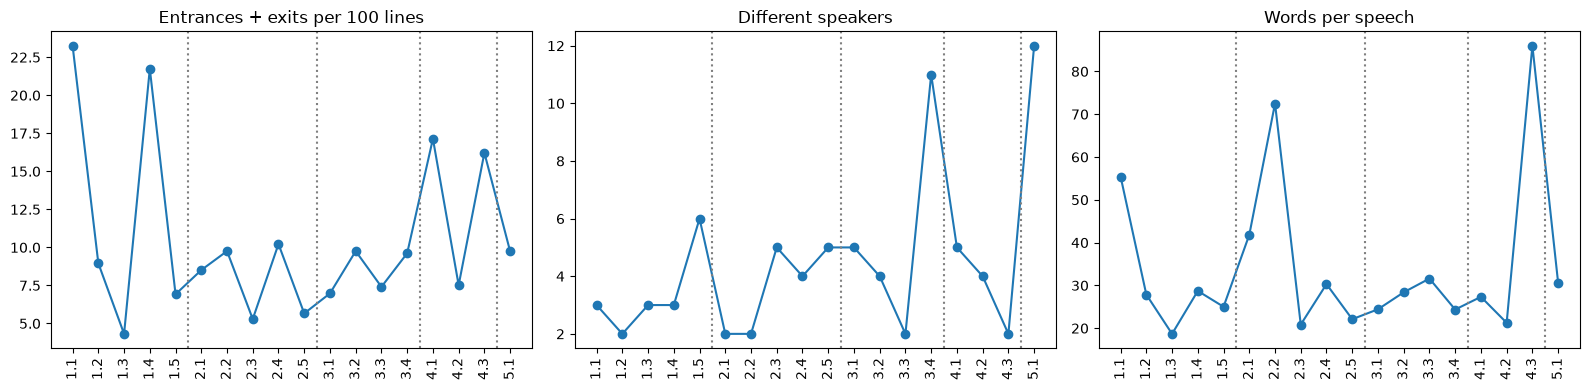

speeches  speakers  words_per_speech  lines  entrances_exits  churn_per_100_lines
act scene                                                                                   
1   1             7         3             55.43     43               10                23.26
    2            21         2             27.86     67                6                 8.96
    3            66         3             18.68    139                6                 4.32
    4            14         3             28.71     46               10                21.74
    5           120         6             25.02    318               22                 6.92
2   1            11         2             41.82     47                4                 8.51
    2             6         2             72.50     41                4                 9.76
    3            84         5             20.86    189               10                 5.29
    4            39         4             30.31    137               14                10.22
    5            84         5             22.11    212               12                 5.66
3   1            66         5             24.42    172               12                 6.98
    2            28         4             28.39     82                8                 9.76
    3            15         2             31.60     54                4                 7.41
    4           154        11             24.36    416               40                 9.62
4   1            24         5             27.33     70               12                17.14
    2            56         4             21.27    133               10                 7.52
    3             4         2             86.00     37                6                16.22
5   1           127        12             30.62    431               42                 9.74

In [13]:
# count speeches, speakers and words for every scene
sc = speeches.groupby(["act", "scene"]).agg(speeches=("sp_id", "count"), speakers=("speaker", "nunique"), words_per_speech=("n_words", "mean"))
lines = ftln_meta.groupby(["act", "scene"]).size().rename("lines")                           # lines per scene
churn = stage_events.groupby(["act", "scene"])["n_chars"].sum().rename("entrances_exits")   # people coming and going
scenes = sc.join([lines, churn]).fillna(0)
scenes["churn_per_100_lines"] = 100 * scenes.entrances_exits / scenes.lines

labels = [f"{a}.{s}" for a, s in scenes.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["churn_per_100_lines", "speakers", "words_per_speech"],
                          ["Entrances + exits per 100 lines", "Different speakers", "Words per speech"]):
    ax.plot(labels, scenes[col], marker="o")
    for i, (a, s) in enumerate(scenes.index):
        if s == 1 and a > 1: ax.axvline(i - 0.5, color="grey", ls=":")     # dotted line = new act
    ax.set_title(title); ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()
scenes.round(2)

## 3.3 RQ2: Orsino's court vs. Olivia's household, and who bridges them
Households come from our character map (Feste, Viola/Cesario and the rest are "neither / both"). For every character we add up their weight to court members and to household members; the **bridge score** is high only if *both* are large.

*In one sentence:* Orsino and Olivia are never on stage together until the last scene, so someone else has to connect them.

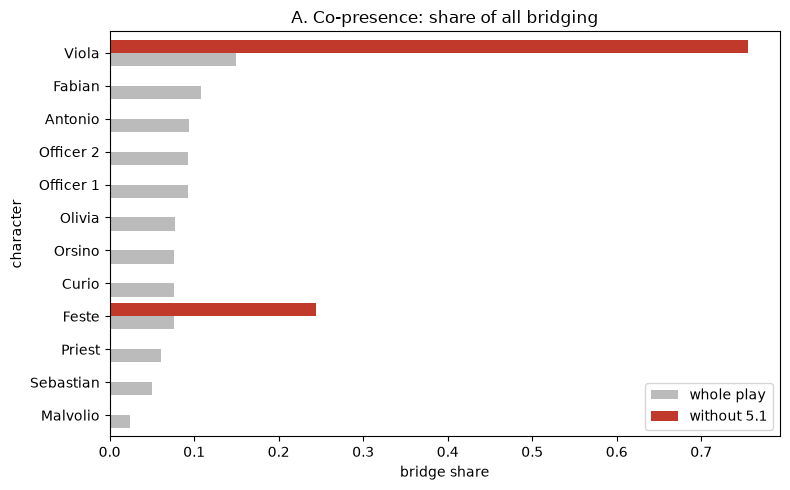

,whole play,without 5.1
character,,
Malvolio,0.02,0.00
Sebastian,0.05,0.00
Priest,0.06,0.00
Feste,0.08,0.24
Curio,0.08,0.00
Orsino,0.08,0.00
Olivia,0.08,0.00
Officer 1,0.09,0.00
Officer 2,0.09,0.00


In [14]:
# rough idea: someone who talks to BOTH sides a lot is acting as a bridge
def bridge_table(M):
    G = to_graph(M); rows = []
    for n in G.nodes:
        wc = sum(G[n][m]["weight"] for m in G[n] if m in COURT and m != n)        # weight to Orsino's court
        wh = sum(G[n][m]["weight"] for m in G[n] if m in HOUSEHOLD and m != n)    # weight to Olivia's household
        rows.append(dict(character=n, side=side(n), to_court=wc, to_household=wh, bridge_score=2 * wc * wh / (wc + wh) if wc and wh else 0))
    t = pd.DataFrame(rows).set_index("character")
    t["bridge_share"] = t.bridge_score / t.bridge_score.sum()
    return t.sort_values("bridge_score", ascending=False)

def without_scene(act_scene, key):
    """The whole play minus one scene, by adding up every other scene's matrix."""
    parts = [build_networks(act=a, scene=s)[key] for a, s in scenes.index if (a, s) != act_scene]
    nodes = sorted(set().union(*[p.index for p in parts]))
    return sum(p.reindex(index=nodes, columns=nodes, fill_value=0) for p in parts)

A_whole = nets["A. Co-presence"]
A_no51 = without_scene((5, 1), "A. Co-presence")      # 5.1 puts almost everyone on stage, so we also look without it

d = pd.DataFrame({"whole play": bridge_table(A_whole).bridge_share, "without 5.1": bridge_table(A_no51).bridge_share}).fillna(0)
d = d[d.max(axis=1) > 0.02].sort_values("whole play")
d.plot.barh(color=["#bbbbbb", "#c0392b"], width=0.8, figsize=(8, 5))
plt.title("A. Co-presence: share of all bridging"); plt.xlabel("bridge share"); plt.tight_layout(); plt.show()
d.round(2)

**When are Orsino and Olivia on stage together?** Lines they share, scene by scene (scenes where they never meet are left out):

In [15]:
# co-presence of just these two, for every scene
for a, s in scenes.index:
    w = copresence(act=a, scene=s)
    if "Orsino" in w.index and "Olivia" in w.columns and w.loc["Orsino", "Olivia"] > 0:
        print(f"Act {a} scene {s}: {w.loc['Orsino', 'Olivia']} lines together")

Act 5 scene 1: 316 lines together


In 5.1 almost everyone is on stage at once, so with that scene nearly everyone looks like a bridge. Without it the picture is sharper. Next, a direct test: **if we remove a character, how much further apart do the two households get?** (Distance between two characters = 1 / weight, averaged over all court-household pairs.)

In [16]:
def cross_distance(G, remove=None):
    H = G.copy()
    if remove in H: H.remove_node(remove)
    for u, v, d in H.edges(data=True): d["dist"] = 1 / d["weight"]       # more interaction = shorter distance
    pairs = [(c, h) for c in COURT for h in HOUSEHOLD if c in H and h in H]
    ds = [nx.shortest_path_length(H, c, h, weight="dist") for c, h in pairs if nx.has_path(H, c, h)]
    return np.mean(ds) if ds else np.nan

rows = []
for label, M in {"whole play": A_whole, "without 5.1": A_no51}.items():
    G = to_graph(M); base = cross_distance(G)
    for cand in ["Viola", "Feste", "Sebastian", "Antonio"]:
        if cand in G:
            rows.append(dict(network=f"A. Co-presence, {label}", removed=cand, distance_increase_pct=round(100 * (cross_distance(G, cand) / base - 1), 1)))
pd.DataFrame(rows).pivot(index="removed", columns="network", values="distance_increase_pct")

network,"A. Co-presence, whole play","A. Co-presence, without 5.1"
removed,,
Antonio,0.0,0.0
Feste,0.0,0.0
Sebastian,0.0,0.0
Viola,0.0,32.4


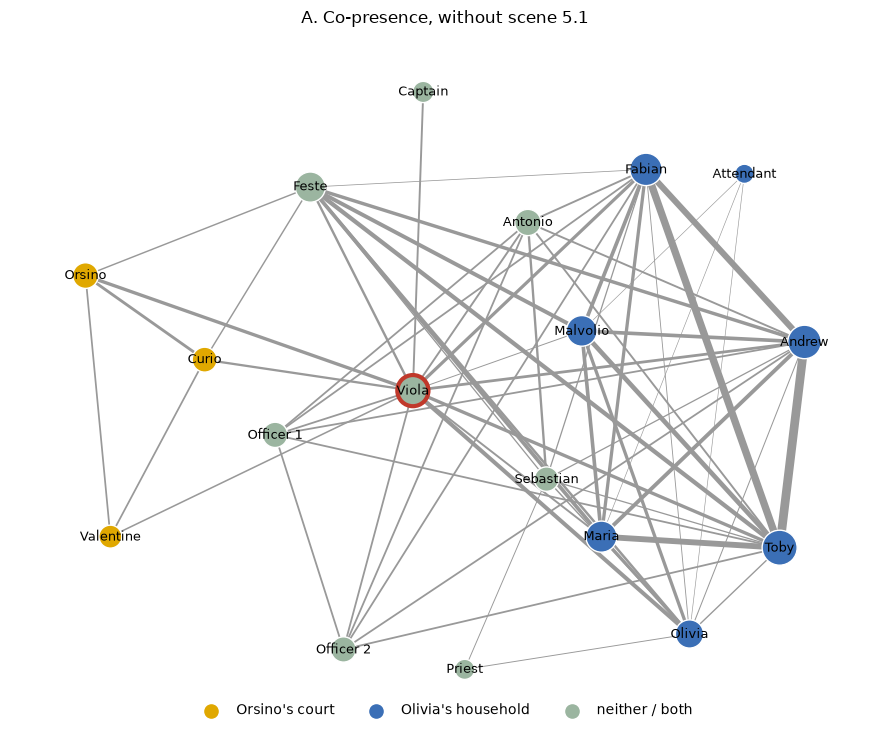

In [17]:
# the co-presence network without scene 5.1, on the same layout
G = to_graph(A_no51); G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
fig, ax = plt.subplots(figsize=(9, 7.5))
draw_net(G, ax, "A. Co-presence, without scene 5.1")
legend(ax); plt.tight_layout(); plt.show()

## 3.4 RQ3: Viola vs. Cesario
We split the node with a transparent rule (`persona_at`): **Viola** in scene 1.2, after her reveal in 5.1, or when nobody but the Captain is watching; **Cesario** whenever anyone else is on stage.

*In one sentence:* splitting her shows that Cesario is the one who meets everyone, while Viola mostly appears alone or with the Captain.

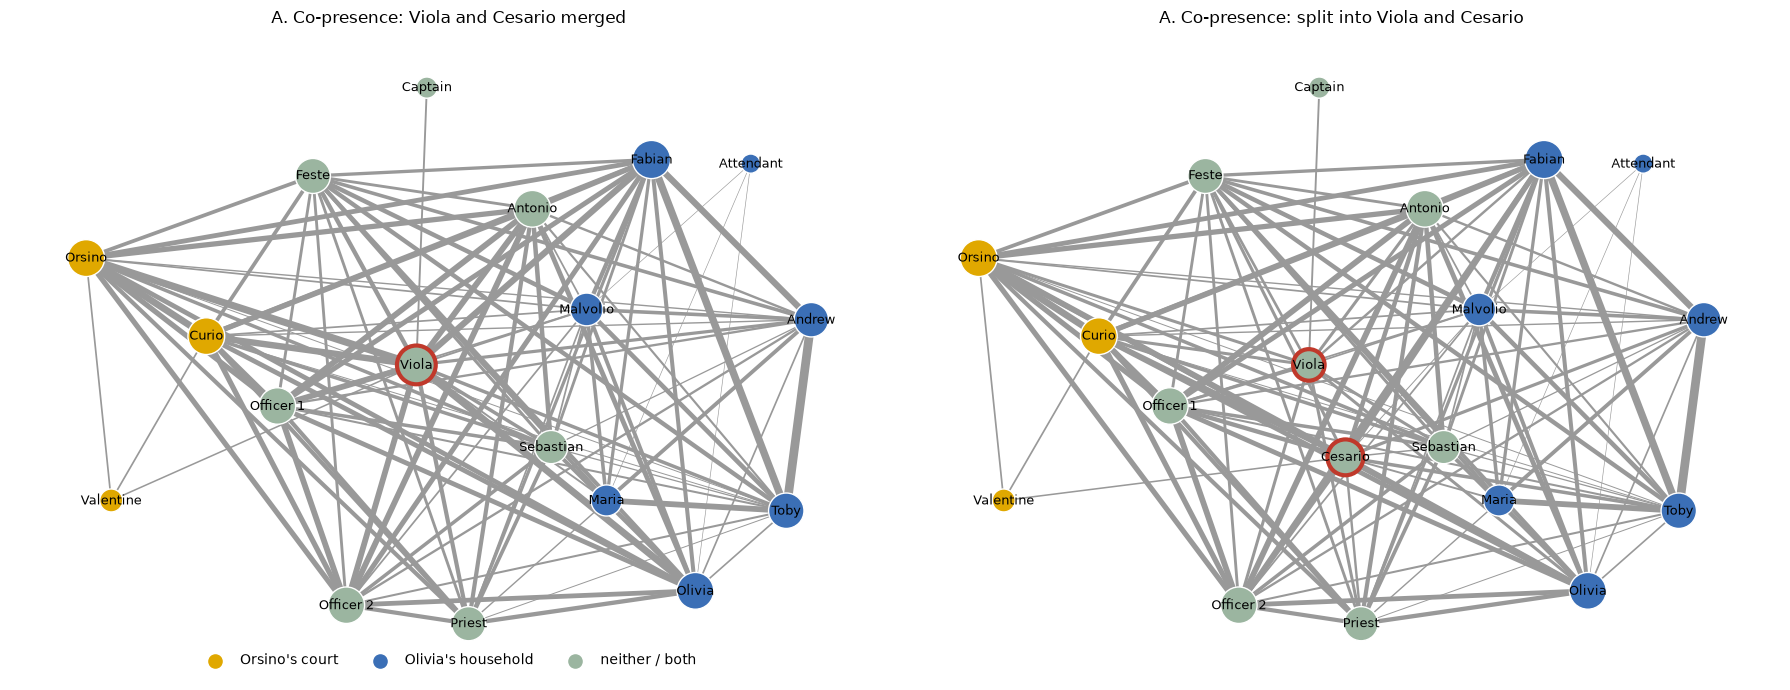

,node,strength,to_court,to_household,betweenness
0,Viola (merged),4726,1122,1530,0.162
1,Cesario,3169,820,1217,0.040
2,Viola (split),1557,302,313,0.111


In [18]:
# same co-presence network, merged vs split
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
draw_net(to_graph(nets["A. Co-presence"]), axes[0], "A. Co-presence: Viola and Cesario merged")
draw_net(to_graph(nets_split["A. Co-presence"]), axes[1], "A. Co-presence: split into Viola and Cesario")
legend(axes[0]); plt.tight_layout(); plt.show()

rows = []
Gm, Gs = to_graph(nets["A. Co-presence"]), to_graph(nets_split["A. Co-presence"])
for label, G, node in [("Viola (merged)", Gm, "Viola"), ("Cesario", Gs, "Cesario"), ("Viola (split)", Gs, "Viola")]:
    if node in G:
        rows.append(dict(node=label, strength=round(G.degree(node, weight="weight")),
                         to_court=round(sum(G[node][m]["weight"] for m in G[node] if m in COURT)),
                         to_household=round(sum(G[node][m]["weight"] for m in G[node] if m in HOUSEHOLD)),
                         betweenness=round(nx.betweenness_centrality(G)[node], 3)))
pd.DataFrame(rows)

**What did the disguise let her do?** Does she speak differently as Cesario? Verse vs. prose and amount of speech for each persona, from the speech table:

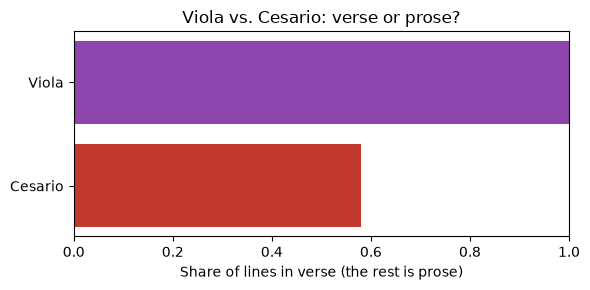

,speeches,words,verse_share
who,,,
Cesario,106,2326,0.58
Viola,16,802,1.00


In [19]:
sp = speeches.copy()
sp["who"] = np.where(sp.speaker == "Viola", sp.persona, sp.speaker)    # Viola's speeches get her persona
v = sp[sp.who.isin(["Viola", "Cesario"])]
register = v.groupby("who").agg(speeches=("sp_id", "count"), words=("n_words", "sum"), verse=("verse_lines", "sum"), prose=("prose_lines", "sum"))
register["verse_share"] = (register.verse / (register.verse + register.prose)).round(2)

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(register.index, register.verse_share, color=["#c0392b", "#8e44ad"])
ax.set_xlim(0, 1); ax.set_xlabel("Share of lines in verse (the rest is prose)"); ax.set_title("Viola vs. Cesario: verse or prose?")
plt.tight_layout(); plt.show()
register[["speeches", "words", "verse_share"]]

## 3.5 Case study: Act 2, Scene 5, the letter scene
Sir Toby, Sir Andrew and Fabian hide. Malvolio reads a forged letter and thinks he is alone. Here is the scene under the two *co-presence-style* rules. **Edge width is on one scale per panel.** Is Malvolio (centre, red) "connected" to the hiding men?

*In one sentence:* both of these rules say yes, even though Malvolio has no idea they are there.

This is the main problem Part 2 picks up: a network that only knows who is on stage cannot tell that the three men are hiding. Myra's speaking networks test whether counting actual conversation fixes it.

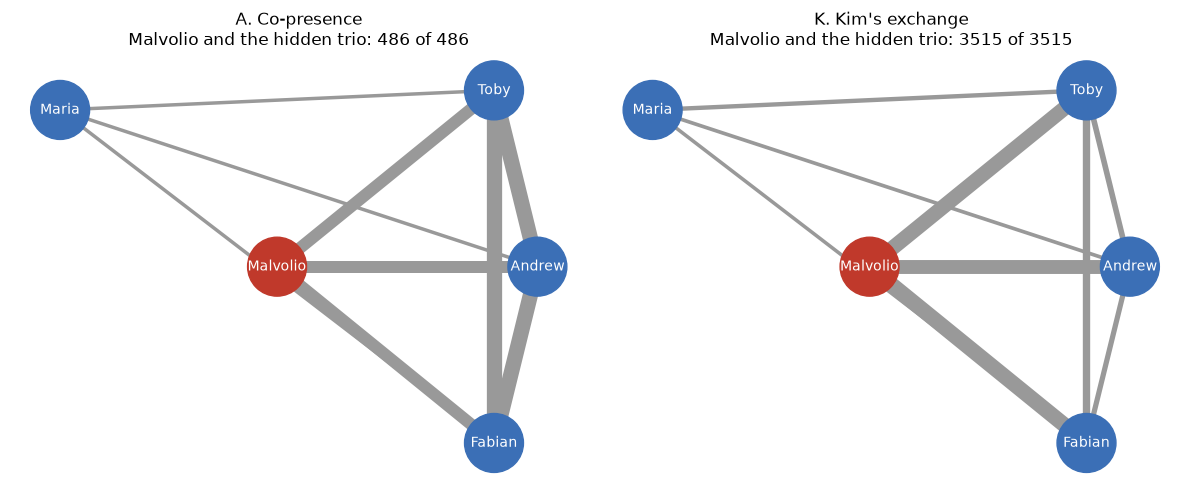

Malvolio speaks 1052 words in 2.5. Kim's rule counts all 1052 as spoken to each of the three hidden men.


,network,malvolio_total,with_the_hidden_trio,share
0,A. Co-presence,486,486,1.0
1,K. Kim's exchange,3515,3515,1.0


In [20]:
# just the five people in the letter scene, easier to read than the whole cast
CASE = ["Malvolio", "TobyBelch", "AndrewAguecheek", "Fabian", "Maria"]
case_pos = {"Malvolio": (0, 0), "TobyBelch": (1.5, 0.9), "AndrewAguecheek": (1.8, 0), "Fabian": (1.5, -0.9), "Maria": (-1.5, 0.8)}
scene25 = build_networks(act=2, scene=5)
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["A. Co-presence", "K. Kim's exchange"]):
    M = scene25[name].reindex(index=CASE, columns=CASE, fill_value=0)
    G = to_graph(M, keep=set(CASE))
    pos = {short(k): v for k, v in case_pos.items()}
    weights = [d["weight"] for _, _, d in G.edges(data=True)]
    nx.draw_networkx(G, pos, ax=ax, node_size=1800, font_size=10, font_color="white", edge_color="#999999",
                     width=[1 + 10 * w / max(weights) for w in weights],
                     node_color=["#c0392b" if n == "Malvolio" else "#3b6fb6" for n in G.nodes])
    tot = M.loc["Malvolio"].sum(); trio = M.loc["Malvolio", CASE[1:4]].sum()
    ax.set_title(f"{name}\nMalvolio and the hidden trio: {trio:.0f} of {tot:.0f}"); ax.axis("off")
    rows.append(dict(network=name, malvolio_total=round(tot), with_the_hidden_trio=round(trio), share=round(trio / tot, 2)))
plt.tight_layout(); plt.show()

mal = speeches[(speeches.act == 2) & (speeches.scene == 5) & (speeches.speaker == "Malvolio")]
print(f"Malvolio speaks {mal.n_words.sum()} words in 2.5. Kim's rule counts all {mal.n_words.sum()} as spoken to each of the three hidden men.")
pd.DataFrame(rows)

# 4. What this part shows
*(Draft for the group to rewrite together in one voice. Check every number against the outputs above before using it.)*

- **RQ1: the stage fills up.** Co-presence density rises every act (0.36, 0.40, 0.50, 0.58, then 0.96 in Act 5), so by the end almost every pair of characters shares the stage. Coming and going does not rise and then settle: entrances and exits per 100 lines are highest in 1.1 (23), 1.4 (22), 4.1 (17) and 4.3 (16), and only 10 in 5.1. The last act "settles" by gathering everyone, not by calming down.
- **RQ2: two households, joined late and by a few.** Orsino and Olivia share the stage only in 5.1 (316 lines). Without that scene, all the bridging comes from Viola/Cesario and Feste, and removing Viola/Cesario pushes the two households about 32% further apart; removing Feste, Sebastian or Antonio changes nothing. Louvain finds two groups that mostly match the households: Toby's circle with Maria, Malvolio and Feste on one side, and Orsino's side on the other. The one exception is Olivia, who is grouped with Orsino's side.
- **RQ3: Cesario is the one who meets everyone.** Cesario has 106 speeches (2,326 words) and links to both the court (820) and the household (1,217). The Viola persona has 16 speeches (802 words), all in verse, and far fewer links (302 and 313). Cesario speaks verse 58% of the time.
- **Kim's rule adds little here.** The "everyone hears" network (K) matches co-presence almost exactly (one edge fewer in Act 5). In scene 2.5, both tie Malvolio entirely to the three men hiding behind him (all 1,052 of his words count as spoken to each of them), even though he thinks he is alone.

**Limitations.** Co-presence shows who is in the room, not who talks to whom. The Viola/Cesario split is a rule of thumb (`persona_at`). The households come from our character map. Louvain and the distance test go beyond the course.

---
# 5. How Part 2 follows on (Myra)

Part 1 shows who shares the stage. Part 2 asks who is actually *talking* to whom, using two speaking networks drawn on the same layout:

- **B1. Next speaker:** a speech counts as spoken to whoever speaks next. This is the method from the course notebook (Week 8, `5-5_TEI_XML_networks`).
- **B2. Addressed:** a speech counts as spoken to the person it is meant for. Asides go to no one, "to Maria"-style stage directions pick the listener, and hidden characters are left out.

Part 2 returns to the questions Part 1 leaves open:
1. **Scene 2.5:** do the speaking networks separate Malvolio from the three hidden men, where co-presence and Kim's rule could not?
2. **Viola/Cesario:** is Cesario still the main bridge between the two households once we count real conversation instead of shared stage time?
3. **Acts 1 to 5:** does talk spread out across the play the way stage presence does?

Because both parts use the same layout and colours, each Part 1 figure can be put next to its Part 2 version.
